In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

dataset load 

In [ ]:

import pandas as pd

df = pd.read_csv("C:\PROJECT\ML\Customer_Churn_AI\Data\Customer_Churn_Prediction.csv")

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Understand Dataset

In [4]:
df.shape

(10000, 14)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [6]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


The figure shows the mean, standard deviation, minimum, and maximum values for the numerical features. CustomerId, Balance, and EstimatedSalary exhibit substantially larger values than the remaining variables, indicating significant differences in feature scales.

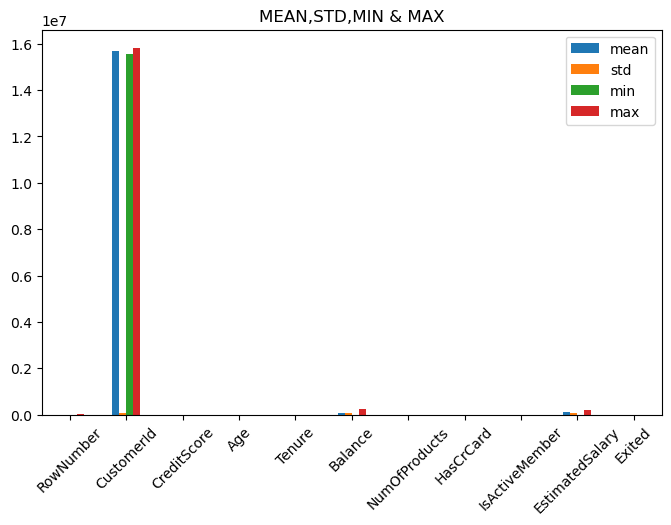

In [7]:

summary = df.describe().T

summary[['mean','std','min','max']].plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('MEAN,STD,MIN & MAX')

plt.xticks(rotation=45)

plt.show()

Check Missing Values

In [8]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [9]:
(df == '?').sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Drop Unnecessary Columns

In [14]:
df.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited'],
      dtype='object')

RowNumber, CustomerId, and Surname were removed during preprocessing because they represent identification attributes rather than customer characteristics. These variables do not contribute meaningful information for predicting customer churn and may introduce unnecessary noise into the model.

In [17]:
#df.drop(
#    ['RowNumber','CustomerId','Surname'],
#    axis=1,
#    inplace=True
#)

In [16]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [18]:
df.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited'],
      dtype='object')

In [19]:
df.tail()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


In [20]:
df.dtypes

CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

Check the number of duplicate rows

In [21]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


Converting the categorical values to integal

In [22]:
df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True)

In [23]:
df.dtypes

CreditScore            int64
Age                    int64
Tenure                 int64
Balance              float64
NumOfProducts          int64
HasCrCard              int64
IsActiveMember         int64
EstimatedSalary      float64
Exited                 int64
Geography_Germany       bool
Geography_Spain         bool
Gender_Male             bool
dtype: object

In [25]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [26]:
df.tail()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
9995,771,39,5,0.00,2,1,0,96270.64,0,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,0,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,1,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,1,True,False,True
9999,792,28,4,130142.79,1,1,0,38190.78,0,False,False,False


In [27]:
df.isnull().sum()

CreditScore          0
Age                  0
Tenure               0
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
Geography_Germany    0
Geography_Spain      0
Gender_Male          0
dtype: int64

In [28]:
df.shape

(10000, 12)

Converting the Boolean columns to integers (0 and 1)

instead of combining Geography into a single integer column.
For Random Forest and Decision Tree, label encoding may still work well. However, when are comparing Logistic Regression, KNN, Decision Tree, and Random Forest in one project, One-Hot Encoding is the best practice and is what i will used for this Project.

In [29]:
bool_cols = ['Geography_Germany', 'Geography_Spain', 'Gender_Male']
df[bool_cols] = df[bool_cols].astype(int)

In [30]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


In [31]:
df.tail()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
9995,771,39,5,0.00,2,1,0,96270.64,0,0,0,1
9996,516,35,10,57369.61,1,1,1,101699.77,0,0,0,1
9997,709,36,7,0.00,1,0,1,42085.58,1,0,0,0
9998,772,42,3,75075.31,2,1,0,92888.52,1,1,0,1
9999,792,28,4,130142.79,1,1,0,38190.78,0,0,0,0


In [32]:
df.dtypes

CreditScore            int64
Age                    int64
Tenure                 int64
Balance              float64
NumOfProducts          int64
HasCrCard              int64
IsActiveMember         int64
EstimatedSalary      float64
Exited                 int64
Geography_Germany      int32
Geography_Spain        int32
Gender_Male            int32
dtype: object

Explore Target Variable

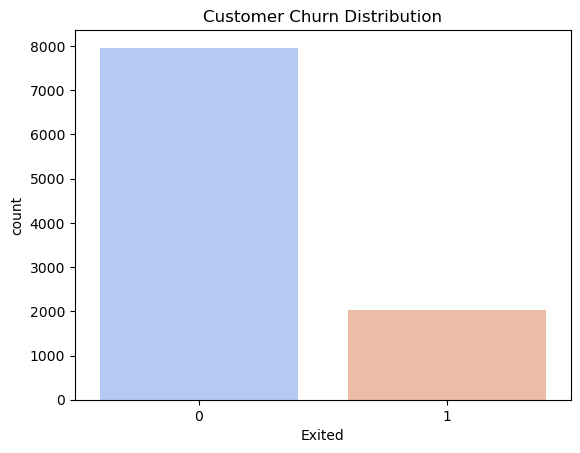

In [33]:
sns.countplot(
    x='Exited',
    data=df,
    palette='coolwarm'
)

plt.title('Customer Churn Distribution')
plt.show()

The correlation heatmap indicates that most variables have weak to moderate relationships with one another, suggesting a low risk of multicollinearity. Age and Balance show positive correlations with customer churn (Exited), while IsActiveMember exhibits a negative correlation, indicating that active customers are less likely to leave the bank. Geography_Germany also demonstrates a positive association with churn. Overall, the absence of strong correlations between predictor variables suggests that the selected features can be retained for model development.

Correlation Heatmap

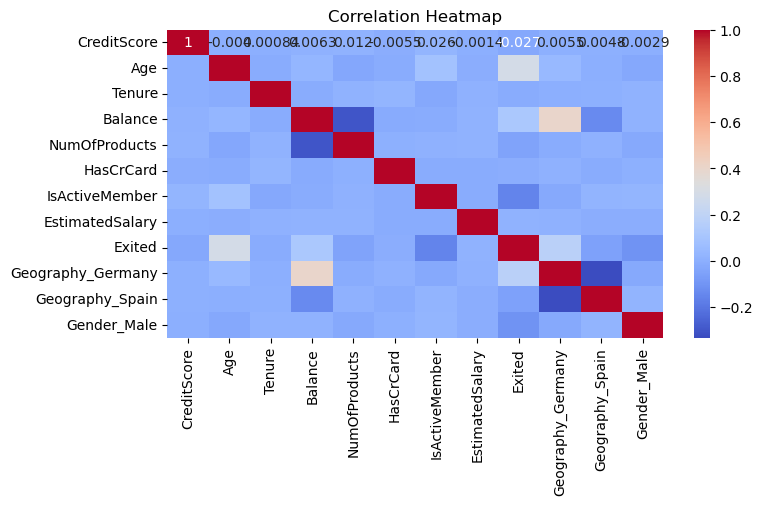

In [34]:
plt.figure(figsize=(8,4))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')

plt.show()

The boxplot illustrates the distribution of the numerical features in the dataset. Balance and EstimatedSalary exhibit the greatest variability, whereas binary variables such as HasCrCard, IsActiveMember, Geography_Germany, Geography_Spain, and Gender_Male are constrained to values between 0 and 1. The substantial differences in feature scales indicate the need for feature normalization or standardization before applying distance-based and gradient-based machine learning algorithms.

Distribution of Features

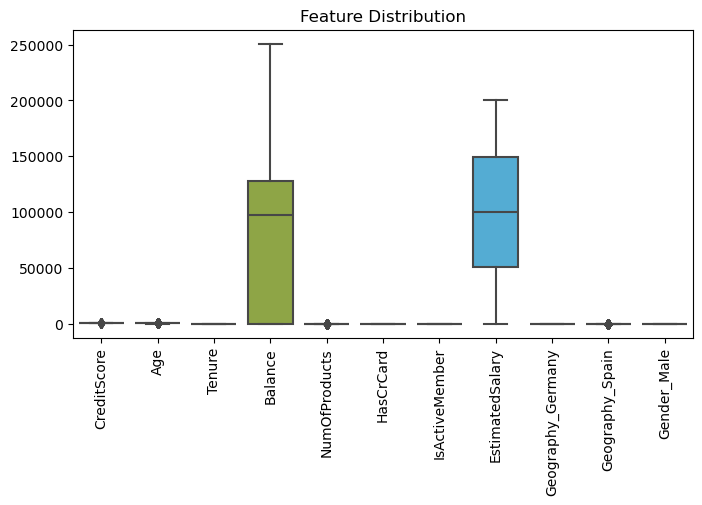

In [35]:
plt.figure(figsize=(8,4))

sns.boxplot(
    data=df.drop('Exited', axis=1)
)

plt.xticks(rotation=90)

plt.title('Feature Distribution')

plt.show()

Define X and y

In [36]:
X = df.drop('Exited', axis=1)

y = df['Exited']

Train Test Split

In [37]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,
    test_size=0.2,
    random_state=42

)

Feature Scaling

Important for:

Logistic Regression
KNN

In [38]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

Train All Models

In [39]:
lr = LogisticRegression()

lr.fit(X_train,y_train)

lr_pred = lr.predict(X_test)

lr_acc = accuracy_score(y_test,lr_pred)

Decision Tree

In [40]:
dt = DecisionTreeClassifier(
    random_state=42
)
dt.fit(X_train,y_train)

dt_pred = dt.predict(X_test)

dt_acc = accuracy_score(y_test,dt_pred)

Random Forest

In [41]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train,y_train)

rf_pred = rf.predict(X_test)

rf_acc = accuracy_score(y_test,rf_pred)

KNN

In [42]:
knn = KNeighborsClassifier(
    n_neighbors=5
)

knn.fit(X_train,y_train)

knn_pred = knn.predict(X_test)

knn_acc = accuracy_score(y_test,knn_pred)

Naive Bayes

In [43]:
nb = GaussianNB()

nb.fit(X_train,y_train)

nb_pred = nb.predict(X_test)

nb_acc = accuracy_score(y_test,nb_pred)

In [44]:
results = pd.DataFrame({

    'Model' : [

        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'KNN',
        'Naive Bayes'

    ],

    'Accuracy' : [

        lr_acc,
        dt_acc,
        rf_acc,
        knn_acc,
        nb_acc
    ]

})

results.sort_values(
    by='Accuracy',
    ascending=False
)

,Model,Accuracy
2,Random Forest,0.8665
4,Naive Bayes,0.8335
3,KNN,0.8300
0,Logistic Regression,0.8110
1,Decision Tree,0.7810


Accuracy Chart

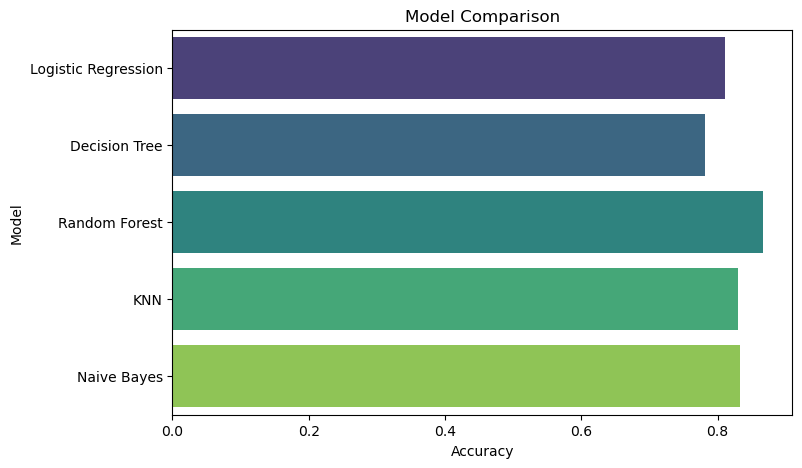

In [45]:
plt.figure(figsize=(8,5))

sns.barplot(
    x='Accuracy',
    y='Model',
    data=results,
    palette='viridis'
)

plt.title('Model Comparison')

plt.show()

Precision Recall F1 for All Models

In [46]:
models = {

    'Logistic Regression': lr_pred,
    'Decision Tree': dt_pred,
    'Random Forest': rf_pred,
    'KNN': knn_pred,
    'Naive Bayes': nb_pred

}

for name,pred in models.items():

    print("\n",name)

    print(classification_report(
        y_test,
        pred
    ))


 Logistic Regression
              precision    recall  f1-score   support

           0       0.83      0.96      0.89      1607
           1       0.55      0.20      0.29       393

    accuracy                           0.81      2000
   macro avg       0.69      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000


 Decision Tree
              precision    recall  f1-score   support

           0       0.87      0.85      0.86      1607
           1       0.45      0.50      0.47       393

    accuracy                           0.78      2000
   macro avg       0.66      0.68      0.67      2000
weighted avg       0.79      0.78      0.79      2000


 Random Forest
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1607
           1       0.76      0.47      0.58       393

    accuracy                           0.87      2000
   macro avg       0.82      0.72      0.75      2000
weighted avg       0

The confusion matrix shows that the model correctly classified 1,550 non-churn customers and 183 churn customers. However, 210 churn customers were incorrectly classified as non-churn, resulting in a recall of 46.56%. Although the model achieved an accuracy of 86.65%, the low recall indicates limited effectiveness in identifying customers at risk of leaving the bank. For customer retention applications, improving recall is essential because missed churn customers represent lost business opportunities.

Best Model Confusion Matrix

Confusion Matrix:
[[1550   57]
 [ 210  183]]


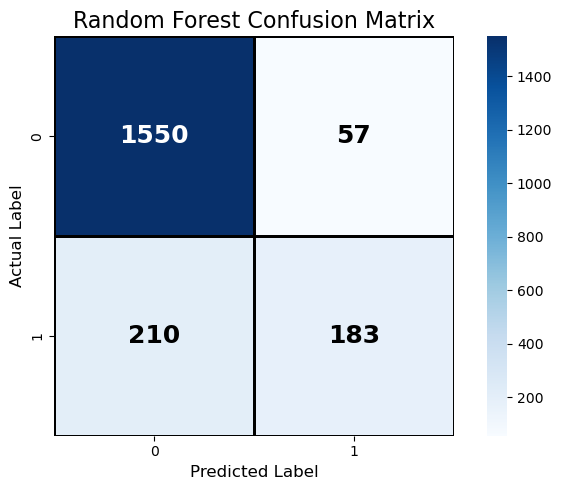

In [55]:

# Clear any previous figures
plt.close('all')

# Stored Random Forest predictions
y_pred_rf = np.asarray(models['Random Forest']).ravel()
y_test_rf = np.asarray(y_test).ravel()

# Create a fixed 2 × 2 confusion matrix
cm = confusion_matrix(
    y_test_rf,
    y_pred_rf,
    labels=[0, 1]
)

# Confirm that all four values exist
print("Confusion Matrix:")
print(cm)

# Create figure
fig, ax = plt.subplots(figsize=(7, 5))

# Draw heatmap without automatic annotations
sns.heatmap(
    cm,
    annot=False,
    cmap='Blues',
    cbar=True,
    linewidths=2,
    linecolor='black',
    square=True,
    xticklabels=['0', '1'],
    yticklabels=['0', '1'],
    ax=ax
)

# Add all four values manually
threshold = cm.max() / 2

for row in range(cm.shape[0]):
    for column in range(cm.shape[1]):

        value = int(cm[row, column])

        # White text on dark cells, black text on light cells
        text_colour = 'white' if value > threshold else 'black'

        ax.text(
            column + 0.5,
            row + 0.5,
            f'{value}',
            horizontalalignment='center',
            verticalalignment='center',
            color=text_colour,
            fontsize=18,
            fontweight='bold',
            zorder=10
        )

# Labels and title
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('Actual Label', fontsize=12)
ax.set_title('Random Forest Confusion Matrix', fontsize=16)

plt.tight_layout()
plt.show()

Further investigation need to be done because of 210 recall

Check Class Distribution

In [56]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [57]:
df['Exited'].value_counts(normalize=True) * 100

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf,
    "KNN": knn,
    "Naive Bayes": nb
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append([
        name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ])

metrics_df = pd.DataFrame(
    results,
    columns=["Model","Accuracy","Precision","Recall","F1"]
)

print(metrics_df)

Try Random Forest with Balanced Classes to Pay more attention to churn customers

In [58]:
from sklearn.ensemble import RandomForestClassifier

rf_balanced = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42
)

rf_balanced.fit(X_train, y_train)

y_pred = rf_balanced.predict(X_test)

In [59]:
RandomForestClassifier(
    class_weight='balanced',
    random_state=42
)

RandomForestClassifier(class_weight='balanced', random_state=42)

Hyperparameter Tuning

The Tuning helps find:

Best number of trees

Best tree depth

Best splitting rules

This often improves Recall and F1 Score

In [61]:
from sklearn.model_selection import GridSearchCV
#from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10]
}

grid = GridSearchCV(
    RandomForestClassifier(
        class_weight='balanced',
        random_state=42
    ),
    param_grid,
    cv=5,
    scoring='recall',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print(grid.best_params_)

{'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 200}


In [62]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10]
}

grid = GridSearchCV(
    RandomForestClassifier(
        class_weight='balanced',
        random_state=42
    ),
    param_grid,
    cv=5,
    scoring='recall',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:")
print(grid.best_params_)

print("Best Recall:")
print(grid.best_score_)

Best Parameters:
{'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 200}
Best Recall:
0.7274835050782118


tuned model

In [64]:
#from sklearn.ensemble import RandomForestClassifier

best_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

# Train the tuned model
best_rf.fit(X_train, y_train)

RandomForestClassifier(max_depth=5, n_estimators=200, n_jobs=-1,
                       random_state=42)

In [66]:
y_pred_tuned = best_rf.predict(X_test)

In [67]:
tuned_acc = accuracy_score(
    y_test,
    y_pred_tuned
)

print("After Tuning Accuracy:", tuned_acc)

After Tuning Accuracy: 0.8505


In [68]:
comparison = pd.DataFrame({

    'Model': [

        'Random Forest (Before Tuning)',
        'Random Forest (After Tuning)'

    ],

    'Accuracy': [

        rf_acc,
        tuned_acc
    ]

})

print(comparison)

                           Model  Accuracy
0  Random Forest (Before Tuning)    0.8665
1   Random Forest (After Tuning)    0.8505


In [69]:
print(classification_report(
    y_test,
    y_pred_tuned
))

              precision    recall  f1-score   support

           0       0.85      0.98      0.91      1607
           1       0.83      0.30      0.44       393

    accuracy                           0.85      2000
   macro avg       0.84      0.64      0.68      2000
weighted avg       0.85      0.85      0.82      2000



Although the tuned Random Forest model achieved good overall accuracy and precision, its recall for class 1 remained low. Therefore, threshold tuning was introduced to improve minority-class detection and achieve a better balance between precision and recall.
Main change: The note clearly connects threshold tuning to the model’s low class 1 recall and the need to reduce missed positive cases.

Confusion Matrix:
[[1582   25]
 [ 274  119]]


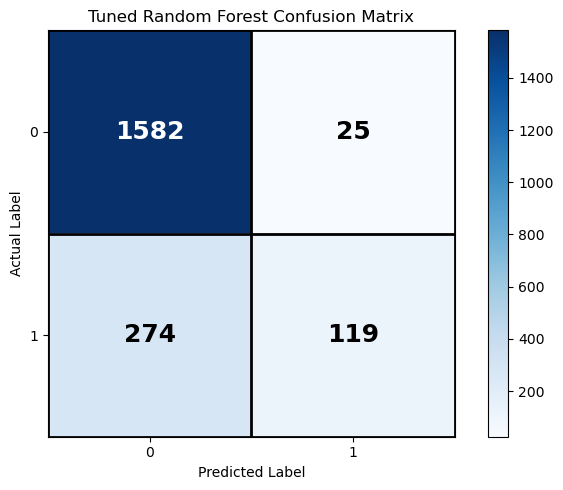

In [73]:

# Create predictions if not already created
y_pred_tuned = best_rf.predict(X_test)

# Convert both arrays to one-dimensional arrays
y_actual = np.asarray(y_test).ravel()
y_pred = np.asarray(y_pred_tuned).ravel()

# Create a fixed 2 × 2 confusion matrix
cm = confusion_matrix(
    y_actual,
    y_pred,
    labels=[0, 1]
)

# Display all four values in the notebook output
print("Confusion Matrix:")
print(cm)

# Create the plot
fig, ax = plt.subplots(figsize=(7, 5))

image = ax.imshow(cm, interpolation='nearest', cmap='Blues')

# Add colour bar
fig.colorbar(image, ax=ax)

# Set axis labels
ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=['0', '1'],
    yticklabels=['0', '1'],
    xlabel='Predicted Label',
    ylabel='Actual Label',
    title='Tuned Random Forest Confusion Matrix'
)

# Determine contrasting text colour
threshold = cm.max() / 2

# Force every value to display
for row in range(2):
    for column in range(2):

        value = int(cm[row, column])

        ax.text(
            column,
            row,
            str(value),
            ha='center',
            va='center',
            color='white' if value > threshold else 'black',
            fontsize=18,
            fontweight='bold'
        )

# Draw borders between cells
ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
ax.grid(which='minor', color='black', linewidth=2)
ax.tick_params(which='minor', bottom=False, left=False)

plt.tight_layout()
plt.show()

In [75]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:",
      accuracy_score(y_test, y_pred_tuned))

print("Precision:",
      precision_score(y_test, y_pred_tuned))

print("Recall:",
      recall_score(y_test, y_pred_tuned))

print("F1-score:",
      f1_score(y_test, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

Accuracy: 0.8505
Precision: 0.8263888888888888
Recall: 0.30279898218829515
F1-score: 0.44320297951582865

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.98      0.91      1607
           1       0.83      0.30      0.44       393

    accuracy                           0.85      2000
   macro avg       0.84      0.64      0.68      2000
weighted avg       0.85      0.85      0.82      2000



ROC-AUC

Accuracy alone can be misleading.

AUC measures how well the model separates:

Churn

Non-Churn

The ROC curve was used to evaluate the classification performance of the Random Forest model across multiple decision thresholds. The model achieved an Area Under the Curve (AUC) score of 0.85, indicating strong discrimination between churning and non-churning customers. Since the AUC value exceeds 0.80, the model demonstrates good predictive capability and can effectively distinguish customers at risk of leaving the bank from those likely to remain.

In [76]:
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
y_prob = rf.predict_proba(X_test)[:,1]

fpr,tpr,threshold = roc_curve(
    y_test,
    y_prob
)

roc_auc = auc(
    fpr,
    tpr
)

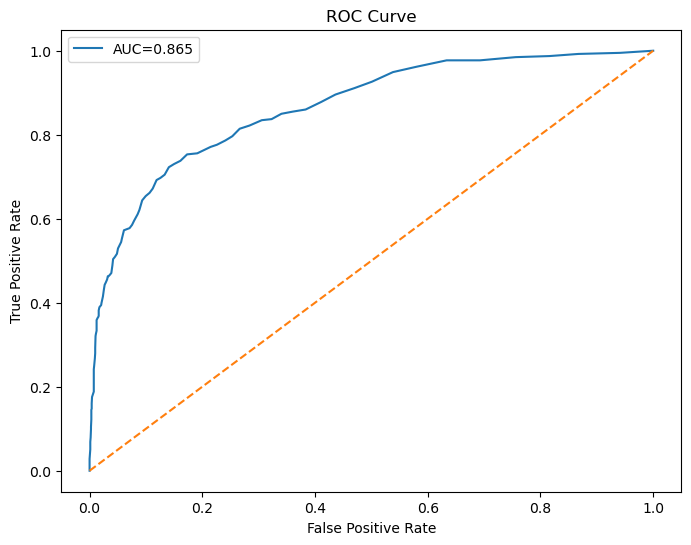

In [77]:
plt.figure(figsize=(8,6))

plt.plot(

    fpr,
    tpr,

    label=f'AUC={roc_auc:.3f}'

)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')

plt.ylabel('True Positive Rate')

plt.title('ROC Curve')

plt.legend()

plt.show()

Threshold Optimization is what needed, not another model.The AUC of 0.8608 already indicates the Random Forest balance weight is learning the churn patterns well; now i will need to choose a threshold that improves Recall and reduces the 210 missed churn customers.

In [78]:
from sklearn.metrics import classification_report

y_prob = best_rf.predict_proba(X_test)[:,1]

for threshold in [0.3, 0.4, 0.5, 0.6,0.7]:
    
    y_pred = (y_prob >= threshold).astype(int)

    print(f"\nThreshold = {threshold}")
    print(classification_report(y_test, y_pred))


Threshold = 0.3
              precision    recall  f1-score   support

           0       0.90      0.92      0.91      1607
           1       0.64      0.59      0.61       393

    accuracy                           0.85      2000
   macro avg       0.77      0.75      0.76      2000
weighted avg       0.85      0.85      0.85      2000


Threshold = 0.4
              precision    recall  f1-score   support

           0       0.88      0.95      0.92      1607
           1       0.71      0.49      0.58       393

    accuracy                           0.86      2000
   macro avg       0.80      0.72      0.75      2000
weighted avg       0.85      0.86      0.85      2000


Threshold = 0.5
              precision    recall  f1-score   support

           0       0.85      0.98      0.91      1607
           1       0.83      0.30      0.44       393

    accuracy                           0.85      2000
   macro avg       0.84      0.64      0.68      2000
weighted avg       0.85

The threshold analysis demonstrates that the default classification threshold of 0.50 was not optimal for identifying customers at risk of churn. At this threshold, the model achieved high precision but detected only 30.28% of actual churners. Reducing the threshold to 0.30 increased recall to 58.78% and produced the highest F1-score of 61.27%, while maintaining an accuracy of 85.40%. Therefore, a threshold of 0.30 was selected because it provides a more appropriate balance between precision and recall and reduces the number of churning customers incorrectly classified as non-churners.

Choosing  the Best Threshold

    Threshold  Accuracy  Precision  Recall      F1
0        0.10    0.4525     0.2599  0.9669  0.4097
1        0.15    0.6540     0.3509  0.8957  0.5043
2        0.20    0.7795     0.4642  0.7913  0.5851
3        0.25    0.8260     0.5455  0.6870  0.6081
4        0.30    0.8540     0.6399  0.5878  0.6127
5        0.35    0.8620     0.6931  0.5344  0.6034
6        0.40    0.8615     0.7148  0.4911  0.5822
7        0.45    0.8595     0.7523  0.4249  0.5431
8        0.50    0.8505     0.8264  0.3028  0.4432
9        0.55    0.8465     0.8839  0.2519  0.3921
10       0.60    0.8415     0.9043  0.2163  0.3491
11       0.65    0.8315     0.9118  0.1578  0.2690
12       0.70    0.8205     0.9722  0.0891  0.1632
13       0.75    0.8135     1.0000  0.0509  0.0969
14       0.80    0.8080     1.0000  0.0229  0.0448
15       0.85    0.8035     0.0000  0.0000  0.0000
16       0.90    0.8035     0.0000  0.0000  0.0000


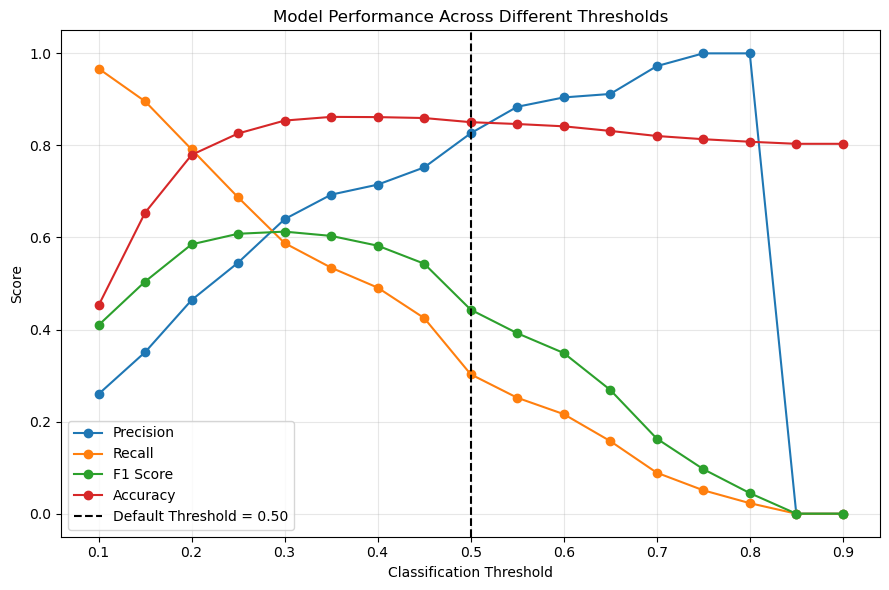

In [80]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Step 1: Get predicted probabilities for class 1
y_probability = best_rf.predict_proba(X_test)[:, 1]

# Step 2: Define thresholds to evaluate
thresholds = np.arange(0.10, 0.91, 0.05)

# Step 3: Store results
results = []

for threshold in thresholds:

    # Convert probabilities into class predictions
    y_pred_threshold = (
        y_probability >= threshold
    ).astype(int)

    results.append({
        'Threshold': threshold,
        'Accuracy': accuracy_score(
            y_test,
            y_pred_threshold
        ),
        'Precision': precision_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        ),
        'Recall': recall_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        ),
        'F1': f1_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        )
    })

# Step 4: Create results_df
results_df = pd.DataFrame(results)

# Display the threshold results
print(results_df.round(4))

# Step 5: Plot the metrics
plt.figure(figsize=(9, 6))

plt.plot(
    results_df['Threshold'],
    results_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    results_df['Threshold'],
    results_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    results_df['Threshold'],
    results_df['F1'],
    marker='o',
    label='F1 Score'
)

plt.plot(
    results_df['Threshold'],
    results_df['Accuracy'],
    marker='o',
    label='Accuracy'
)

plt.axvline(
    x=0.50,
    color='black',
    linestyle='--',
    label='Default Threshold = 0.50'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Model Performance Across Different Thresholds')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Following hyperparameter tuning and classification-threshold optimisation, the tuned Random Forest model with a threshold of 0.30 was selected as the final model. It achieved an accuracy of 85.40%, precision of 63.99%, recall of 58.78%, and an F1-score of 61.27% for the churn class. The model correctly identified 231 of the 393 customers who churned, representing a substantial improvement over the default threshold of 0.50. Although lowering the threshold increased false-positive predictions, it reduced the number of missed churners and provided a better balance between precision and recall. Therefore, the tuned Random Forest model with a threshold of 0.30 was considered the most appropriate model among the evaluated alternatives for customer churn prediction.

Final prediction

In [81]:
# Predicted churn probabilities
y_probability = best_rf.predict_proba(X_test)[:, 1]

# Apply the selected threshold
final_threshold = 0.30
y_pred_final = (y_probability >= final_threshold).astype(int)

Final evaluation

In [82]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Final Tuned Random Forest")
print("Selected Threshold:", final_threshold)
print("Accuracy:", accuracy_score(y_test, y_pred_final))
print("Precision:", precision_score(y_test, y_pred_final))
print("Recall:", recall_score(y_test, y_pred_final))
print("F1-score:", f1_score(y_test, y_pred_final))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

Final Tuned Random Forest
Selected Threshold: 0.3
Accuracy: 0.854
Precision: 0.6398891966759003
Recall: 0.5877862595419847
F1-score: 0.6127320954907162

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.92      0.91      1607
           1       0.64      0.59      0.61       393

    accuracy                           0.85      2000
   macro avg       0.77      0.75      0.76      2000
weighted avg       0.85      0.85      0.85      2000


Confusion Matrix:
[[1477  130]
 [ 162  231]]


Feature Importance